# **Important Imports**

In [1]:
# %pip install xlrd

In [2]:
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
from sklearn.linear_model import Lasso, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

import warnings
warnings.filterwarnings('ignore')

# **Data Understanding**

In [3]:
df = pd.read_excel(r"..\data\Concrete_Data.xls")

In [4]:
df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)  

In [6]:
df.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


# **EDA**

<Figure size 4000x4000 with 0 Axes>

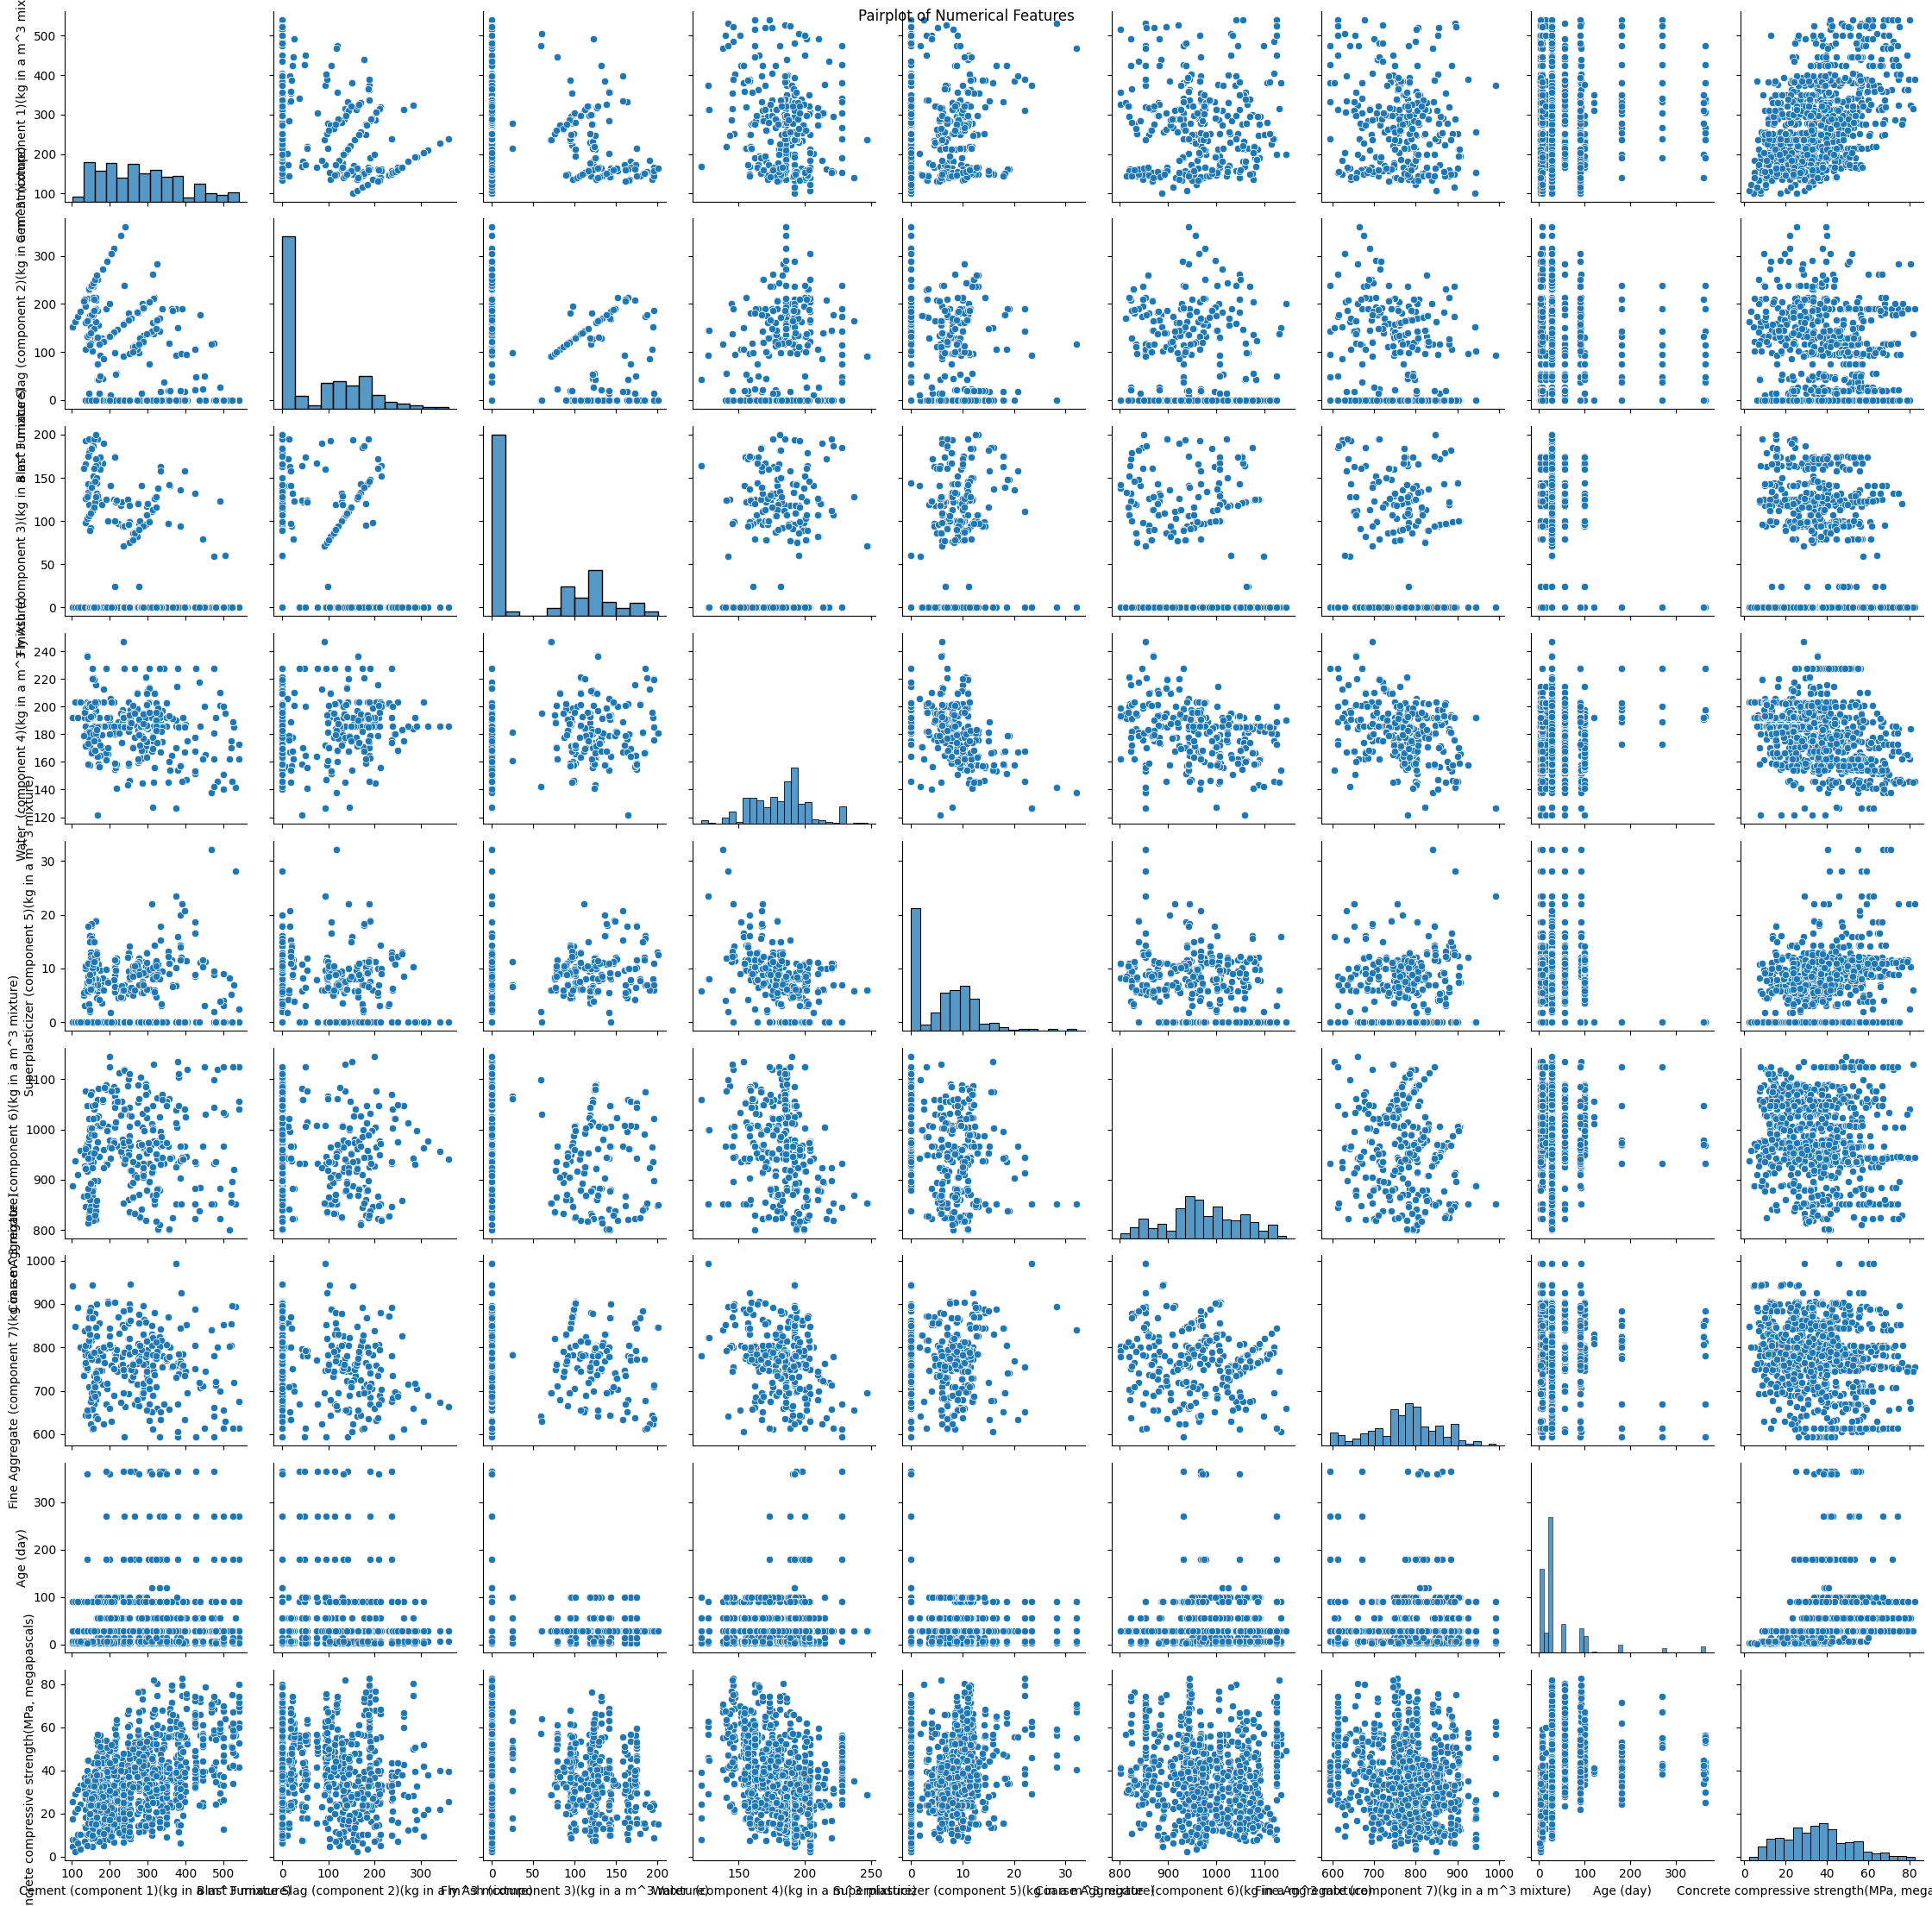

In [7]:
plt.figure(figsize=(40, 40))
sns.pairplot(df,)
plt.suptitle('Pairplot of Numerical Features')
plt.tight_layout()
plt.show()

In [8]:
df.isnull().sum()

Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(25)

In [10]:
len(df)

1030

In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
len(df)

1005

In [14]:
df.columns

Index(['Cement (component 1)(kg in a m^3 mixture)',
       'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
       'Fly Ash (component 3)(kg in a m^3 mixture)',
       'Water  (component 4)(kg in a m^3 mixture)',
       'Superplasticizer (component 5)(kg in a m^3 mixture)',
       'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
       'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)',
       'Concrete compressive strength(MPa, megapascals) '],
      dtype='object')

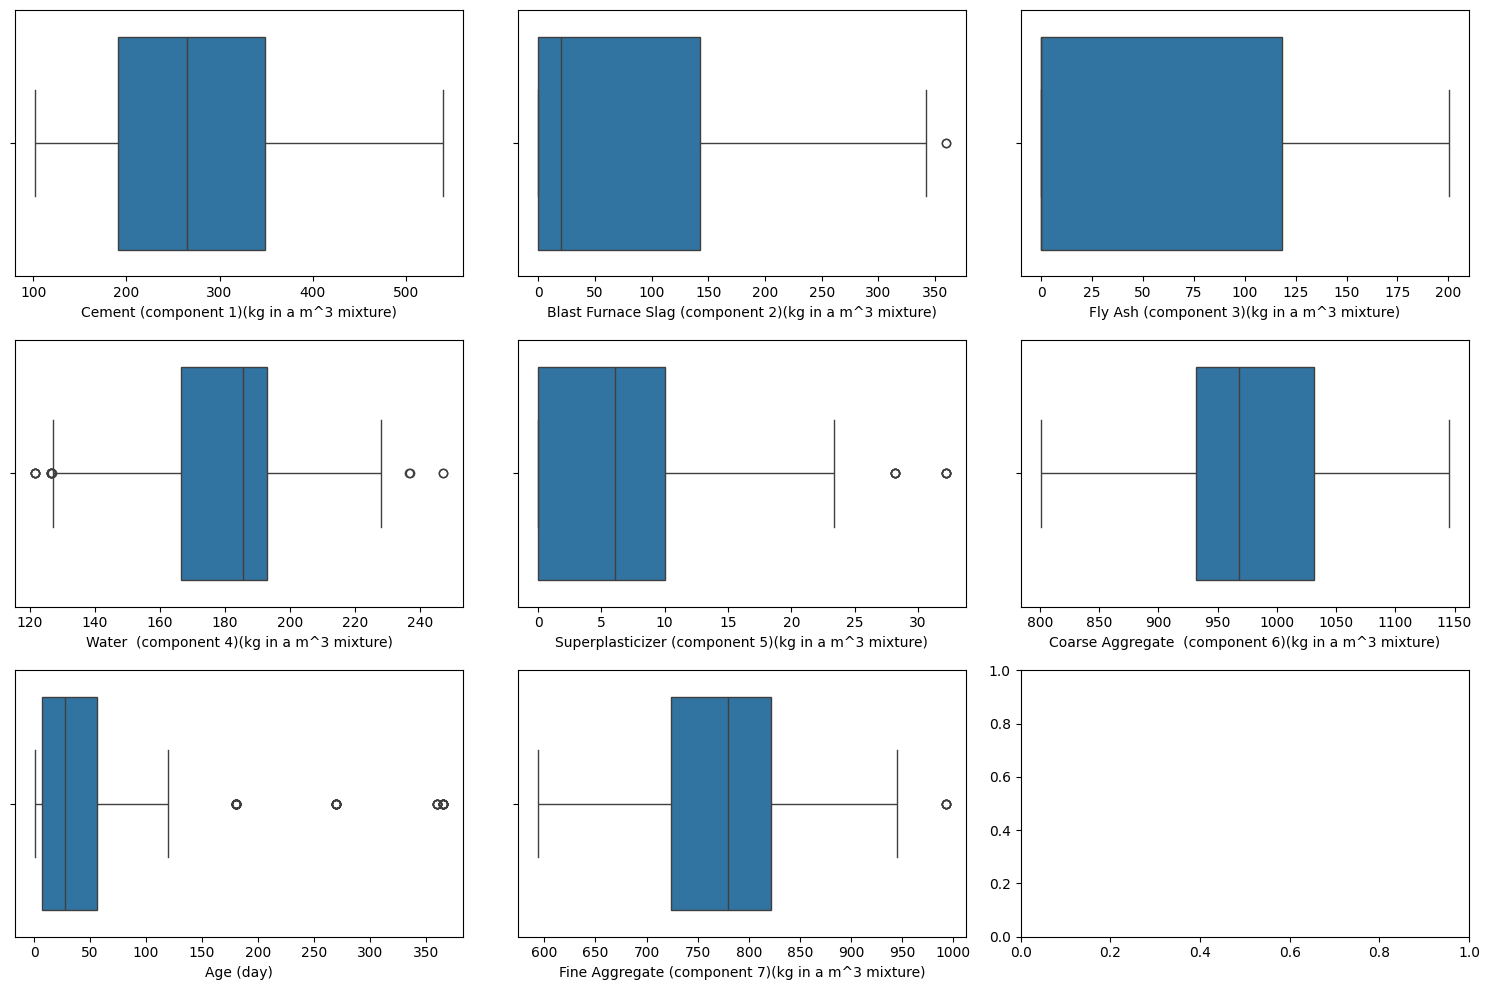

In [15]:
figure, axes = plt.subplots(3, 3, figsize=(15, 10))

sns.boxplot(x= "Cement (component 1)(kg in a m^3 mixture)", data=df, ax=axes[0, 0])
sns.boxplot(x= "Blast Furnace Slag (component 2)(kg in a m^3 mixture)", data=df, ax=axes[0, 1])
sns.boxplot(x= "Fly Ash (component 3)(kg in a m^3 mixture)", data=df, ax=axes[0, 2])
sns.boxplot(x= "Water  (component 4)(kg in a m^3 mixture)", data=df, ax=axes[1, 0])
sns.boxplot(x= "Superplasticizer (component 5)(kg in a m^3 mixture)", data=df, ax=axes[1, 1])
sns.boxplot(x= "Coarse Aggregate  (component 6)(kg in a m^3 mixture)", data=df, ax=axes[1, 2])
sns.boxplot(x= "Age (day)", data=df, ax=axes[2, 0])
sns.boxplot(x= "Fine Aggregate (component 7)(kg in a m^3 mixture)", data=df, ax=axes[2, 1])

plt.tight_layout()
plt.show()

# **Splitting**

In [16]:
x = df.drop(columns=["Concrete compressive strength(MPa, megapascals) "])
y = df["Concrete compressive strength(MPa, megapascals) "]

In [17]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [18]:
display(x_train.shape)
display(y_train.shape)

print("--"*25)

display(x_test.shape)
display(y_test.shape)

(804, 8)

(804,)

--------------------------------------------------


(201, 8)

(201,)

# **Preprocessing**

In [19]:
rs = RobustScaler()

In [20]:
x_train_scaled = pd.DataFrame(rs.fit_transform(x_train), columns=x_train.columns)
x_test_scaled = pd.DataFrame(rs.transform(x_test), columns=x_test.columns)

In [21]:
x_train_scaled.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day)
0,1.675280,-0.142526,0.000000,-1.717024,2.2085,-1.202282,1.178251,-0.595238
1,1.320434,-0.142526,0.000000,1.654444,-0.6115,-0.373444,-1.933091,-0.500000
2,0.072797,-0.142526,0.823176,-0.981715,0.5715,0.061203,0.990449,-0.595238
3,1.074625,-0.142526,0.000000,1.263323,-0.6115,-1.344398,-0.628134,0.000000
4,-0.622085,1.640477,0.000000,0.696196,-0.6115,0.078838,-0.909473,-0.500000


In [22]:
x_test_scaled.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day)
0,-0.710954,0.888651,0.0,-0.297252,0.1885,0.328838,0.435972,0.00000
1,-0.900668,1.168003,0.0,0.696196,-0.6115,-0.101660,0.206540,0.00000
2,-0.709063,0.584358,0.0,0.246407,-0.6115,-0.829876,1.691098,1.47619
3,1.351948,-0.142526,0.0,0.246407,-0.6115,-0.329876,-0.705995,-0.50000
4,1.478634,-0.142526,0.0,0.559304,-0.3115,1.622407,-1.733766,0.00000


# **Modeling**

In [23]:
LR = LinearRegression()

LR.fit(x_train_scaled, y_train)
y_pred = LR.predict(x_test_scaled)
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Absolute Error: 8.896027820458997
Mean Squared Error: 125.265338276725
Root Mean Squared Error: 11.19219988548833
R2 Score: 0.580108901995383


In [24]:
model_lasso = Lasso(alpha=0.1)
model_lasso.fit(x_train_scaled, y_train)
y_pred_lasso = model_lasso.predict(x_test_scaled)
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred_lasso))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_lasso))
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test, y_pred_lasso)))
print("R2 Score:", r2_score(y_test, y_pred_lasso))

Mean Absolute Error: 8.933997702283186
Mean Squared Error: 126.45719436258199
Root Mean Squared Error: 11.24531877549863
R2 Score: 0.5761137843719554


In [25]:
model_ridge = Ridge(alpha=0.1)
model_ridge.fit(x_train_scaled, y_train)
y_pred_ridge = model_ridge.predict(x_test_scaled)
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred_ridge))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_ridge))
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test, y_pred_ridge)))
print("R2 Score:", r2_score(y_test, y_pred_ridge))

Mean Absolute Error: 8.89628399603528
Mean Squared Error: 125.27262415425292
Root Mean Squared Error: 11.192525369828425
R2 Score: 0.5800844796359561


In [26]:
poly_model = make_pipeline(PolynomialFeatures(degree=3), LinearRegression())
poly_model.fit(x_train_scaled, y_train)
y_pred_poly = poly_model.predict(x_test_scaled)
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred_poly))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_poly))
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test, y_pred_poly)))
print("R2 Score:", r2_score(y_test, y_pred_poly))

Mean Absolute Error: 4.502015923438035
Mean Squared Error: 35.38369972963924
Root Mean Squared Error: 5.948419935549207
R2 Score: 0.881393362798235


In [27]:
poly_model_lasso = make_pipeline(PolynomialFeatures(degree=3), Lasso(alpha=0.1))
poly_model_lasso.fit(x_train_scaled, y_train)
y_pred_poly_lasso = poly_model_lasso.predict(x_test_scaled)
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred_poly_lasso))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_poly_lasso))
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test, y_pred_poly_lasso)))
print("R2 Score:", r2_score(y_test, y_pred_poly_lasso))

Mean Absolute Error: 5.288535416050915
Mean Squared Error: 51.904461473662415
Root Mean Squared Error: 7.204475100495692
R2 Score: 0.8260155473226871


In [28]:
poly_model_ridge = make_pipeline(PolynomialFeatures(degree=3), Ridge(alpha=0.1))
poly_model_ridge.fit(x_train_scaled, y_train)
y_pred_poly_ridge = poly_model_ridge.predict(x_test_scaled)
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred_poly_ridge))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_poly_ridge))
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test, y_pred_poly_ridge)))
print("R2 Score:", r2_score(y_test, y_pred_poly_ridge))

Mean Absolute Error: 4.55232543892904
Mean Squared Error: 37.74231525357533
Root Mean Squared Error: 6.143477456097266
R2 Score: 0.8734872518521373


In [29]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib
import seaborn as sns
import xlrd

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("xlrd:", xlrd.__version__)
import streamlit as st

print("Streamlit:", st.__version__)

Pandas: 2.3.3
NumPy: 2.3.5
Scikit-learn: 1.7.2
Matplotlib: 3.10.6
Seaborn: 0.13.2
xlrd: 2.0.2
Streamlit: 1.51.0


In [30]:
poly_model = make_pipeline(
    RobustScaler(),
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
)

poly_model.fit(x_train, y_train)
y_pred = poly_model.predict(x_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Absolute Error: 4.502015923438023
Mean Squared Error: 35.38369972963635
Root Mean Squared Error: 5.948419935548965
R2 Score: 0.8813933627982447


In [31]:
# import joblib
# joblib.dump(poly_model, "../models/best_model.pkl")

In [32]:
import joblib

model_bundle = {
    "model": poly_model,
    "feature_names": x_train.columns.tolist(),
    "feature_stats": {
        "min": x_train.min().to_dict(),
        "max": x_train.max().to_dict(),
        "mean": x_train.mean().to_dict()
    }
}

joblib.dump(model_bundle, "../models/best_model.pkl")

['../models/best_model.pkl']

In [36]:
model_bundle["feature_stats"]["min"]

{'Cement (component 1)(kg in a m^3 mixture)': 102.0,
 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)': 0.0,
 'Fly Ash (component 3)(kg in a m^3 mixture)': 0.0,
 'Water  (component 4)(kg in a m^3 mixture)': 121.75,
 'Superplasticizer (component 5)(kg in a m^3 mixture)': 0.0,
 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)': 801.0,
 'Fine Aggregate (component 7)(kg in a m^3 mixture)': 594.0,
 'Age (day)': 1.0}